In [1]:

import requests
import xml.etree.ElementTree as ET
from datetime import datetime, timezone, timedelta
from urllib.parse import quote

search_terms = [
    "solar energy",
    "solar panels",
    "solar power",
    "solar technology"
]

articles = {}

for term in search_terms:
    url = (
        "https://news.google.com/rss/search?q="
        + quote(term + " when:1d")
        + "&hl=en-US&gl=US&ceid=US:en"
    )

    response = requests.get(url, timeout=20)
    response.raise_for_status()

    root = ET.fromstring(response.content)
    items = root.findall(".//item")

    print(term, ":", len(items), "articles")

    for item in items:
        title = item.findtext("title", "")
        link = item.findtext("link", "")
        date = item.findtext("pubDate", "")

        articles[link or title] = {
            "title": title,
            "date": date
        }

print("\nUnique articles:", len(articles))
print("\nExample titles:")

for article in list(articles.values())[:5]:
    print("-", article["title"])


solar energy : 100 articles
solar panels : 100 articles
solar power : 100 articles
solar technology : 100 articles

Unique articles: 206

Example titles:
- Published at Solar Energy - Techno-economic comparative analysis of hybrid PV-CSP systems: particle vs. molten salt based layouts integrated with sCO2 power blocks - SolarPACES
- London Stadium Hits Solar Energy Milestone - stadiaworld
- Qcells aims to build a giant factory for next-gen tandem solar - Canary Media
- Hawai‘i energy forum launches online series on solar farming, disaster resilience and LNG - Maui Now
- EDITORIAL: Taxpayers singed by subsidies to failed solar plant - Las Vegas Review-Journal


In [2]:

from email.utils import parsedate_to_datetime
from datetime import datetime, timezone, timedelta

now = datetime.now(timezone.utc)
last_24_hours = now - timedelta(hours=24)

recent_articles = []

for article in articles.values():
    try:
        published = parsedate_to_datetime(
            article["date"]
        )

        if last_24_hours <= published <= now:
            recent_articles.append(article)

    except (ValueError, TypeError):
        continue

print("Articles from last 24 hours:", len(recent_articles))

print("\nExample recent articles:")
for article in recent_articles[:5]:
    print("-", article["title"])


Articles from last 24 hours: 204

Example recent articles:
- Published at Solar Energy - Techno-economic comparative analysis of hybrid PV-CSP systems: particle vs. molten salt based layouts integrated with sCO2 power blocks - SolarPACES
- London Stadium Hits Solar Energy Milestone - stadiaworld
- Qcells aims to build a giant factory for next-gen tandem solar - Canary Media
- Hawai‘i energy forum launches online series on solar farming, disaster resilience and LNG - Maui Now
- EDITORIAL: Taxpayers singed by subsidies to failed solar plant - Las Vegas Review-Journal


In [3]:

!pip -q install transformers torch

from transformers import pipeline

sentiment_model = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-roberta-base-sentiment-latest",
    device=-1
)

# Test met vijf echte nieuwstitels
for article in recent_articles[:5]:
    result = sentiment_model(
        article["title"],
        truncation=True
    )[0]

    print("ARTICLE:", article["title"])
    print("SENTIMENT:", result["label"])
    print("CONFIDENCE:", round(result["score"], 2))
    print("-----------------------------")


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

model.safetensors: downloading bytes:           |  0.00B            

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

ARTICLE: Published at Solar Energy - Techno-economic comparative analysis of hybrid PV-CSP systems: particle vs. molten salt based layouts integrated with sCO2 power blocks - SolarPACES
SENTIMENT: neutral
CONFIDENCE: 0.9
-----------------------------
ARTICLE: London Stadium Hits Solar Energy Milestone - stadiaworld
SENTIMENT: positive
CONFIDENCE: 0.67
-----------------------------
ARTICLE: Qcells aims to build a giant factory for next-gen tandem solar - Canary Media
SENTIMENT: neutral
CONFIDENCE: 0.59
-----------------------------
ARTICLE: Hawai‘i energy forum launches online series on solar farming, disaster resilience and LNG - Maui Now
SENTIMENT: neutral
CONFIDENCE: 0.9
-----------------------------
ARTICLE: EDITORIAL: Taxpayers singed by subsidies to failed solar plant - Las Vegas Review-Journal
SENTIMENT: negative
CONFIDENCE: 0.67
-----------------------------


In [4]:

import pandas as pd

results = []

for article in recent_articles:
    prediction = sentiment_model(
        article["title"],
        truncation=True
    )[0]

    results.append({
        "title": article["title"],
        "date": article["date"],
        "sentiment": prediction["label"],
        "confidence": round(prediction["score"], 2)
    })

df = pd.DataFrame(results)

df.to_csv("solarmood.csv", index=False)

print("Saved", len(df), "articles!")
df.head()


Saved 204 articles!


,title,date,sentiment,confidence
0,Published at Solar Energy - Techno-economic co...,"Tue, 13 Oct 2026 06:09:14 GMT",neutral,0.90
1,London Stadium Hits Solar Energy Milestone - s...,"Tue, 13 Oct 2026 08:33:23 GMT",positive,0.67
2,Qcells aims to build a giant factory for next-...,"Tue, 13 Oct 2026 07:00:00 GMT",neutral,0.59
3,Hawai‘i energy forum launches online series on...,"Mon, 12 Oct 2026 23:00:00 GMT",neutral,0.90
4,EDITORIAL: Taxpayers singed by subsidies to fa...,"Tue, 13 Oct 2026 04:00:00 GMT",negative,0.67


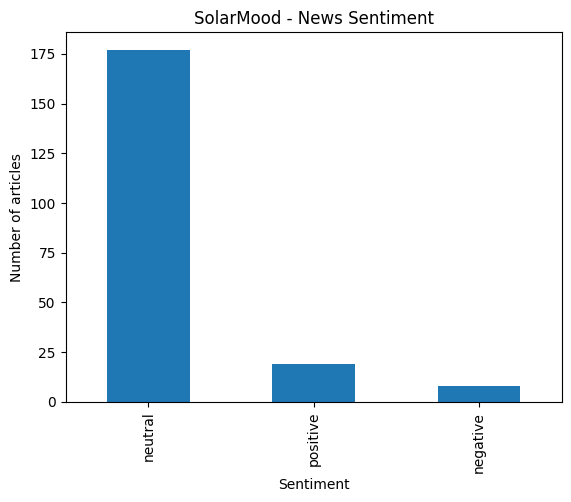

In [5]:

import matplotlib.pyplot as plt

# Count the sentiment labels
counts = df["sentiment"].value_counts()

# Create a bar chart
counts.plot(kind="bar")

plt.title("SolarMood - News Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of articles")
plt.show()


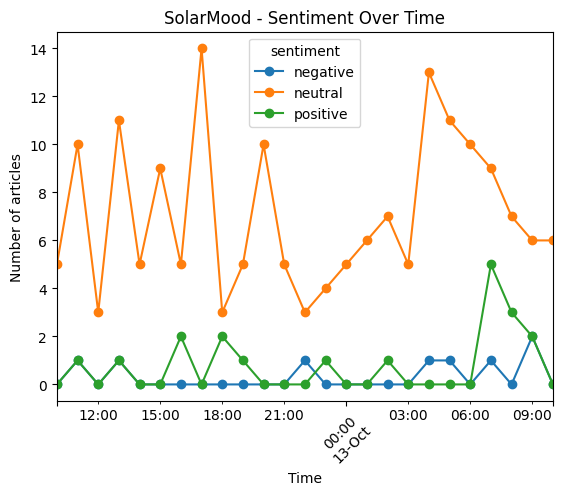

In [6]:

# Convert dates into hours
df["hour"] = pd.to_datetime(df["date"], utc=True).dt.floor("h")

# Count sentiments per hour
hourly = df.groupby(["hour", "sentiment"]).size().unstack(fill_value=0)

# Create the chart
hourly.plot(kind="line", marker="o")

plt.title("SolarMood - Sentiment Over Time")
plt.xlabel("Time")
plt.ylabel("Number of articles")
plt.xticks(rotation=45)
plt.show()
